# Đồ thị 14 Bubble của tám nhóm tuổi và giới tính

**Võ Minh Huy — 2311110117**

Tổng hợp đủ 299 hồ sơ thành tám nhóm tuổi–giới tính. Trục X là EF trung bình (%), trục Y là serum_creatinine trung bình (mg/dL). Diện tích bong bóng tỷ lệ thuận với số hồ sơ của nhóm; màu phân biệt nữ và nam. Mỗi bong bóng là một nhóm, không phải một bệnh nhân.

Không dùng nhãn DEATH_EVENT nên vẫn bao gồm hồ sơ chờ xác minh. Dùng EF và creatinine đã làm sạch, không dùng hai cột platelets làm mịn. Không dịch tọa độ để tách các nhóm gần nhau.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
cot = ["age","MaNhomTuoi","sex","ejection_fraction","serum_creatinine"]
du_lieu[cot] = du_lieu[cot].apply(pd.to_numeric,errors="raise")
if len(du_lieu) != 299 or du_lieu[cot].isna().any().any() or not np.isfinite(du_lieu[cot]).all().all():
    raise ValueError("Cần đủ 299 hồ sơ không thiếu các chỉ số dùng để tổng hợp.")
assert du_lieu["sex"].isin([0,1]).all() and du_lieu["age"].between(40,95).all()
assert du_lieu["ejection_fraction"].between(0,100).all() and (du_lieu["serum_creatinine"]>0).all()
ma_tu_tuoi = np.select([du_lieu["age"]<50,du_lieu["age"]<60,du_lieu["age"]<70],[1,2,3],default=4)
assert np.array_equal(ma_tu_tuoi,du_lieu["MaNhomTuoi"].to_numpy())
bang_tong_hop = du_lieu.groupby(["MaNhomTuoi","sex"],sort=True).agg(
    SoHoSo=("MaHoSo","size"),EFMean=("ejection_fraction","mean"),CreatinineMean=("serum_creatinine","mean")).reset_index()
bang_tong_hop["GioiTinh"] = bang_tong_hop["sex"].map({0:"Nữ",1:"Nam"})
assert len(bang_tong_hop)==8 and bang_tong_hop["SoHoSo"].sum()==299
assert bang_tong_hop["SoHoSo"].tolist()==[18,24,27,50,38,73,22,47]
for mean_cot, cot_goc in [("EFMean","ejection_fraction"),("CreatinineMean","serum_creatinine")]:
    assert np.isclose(np.average(bang_tong_hop[mean_cot],weights=bang_tong_hop["SoHoSo"]),du_lieu[cot_goc].mean())
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/14_bubble_nhom"
thu_muc_kq.mkdir(parents=True,exist_ok=True)
bang_tong_hop[["MaNhomTuoi","GioiTinh","SoHoSo","EFMean","CreatinineMean"]].round(2)


,MaNhomTuoi,GioiTinh,SoHoSo,EFMean,CreatinineMean
0,1,Nữ,18,40.33,1.15
1,1,Nam,24,35.71,1.14
2,2,Nữ,27,37.37,1.43
3,2,Nam,50,38.12,1.20
4,3,Nữ,38,40.00,1.67
5,3,Nam,73,37.05,1.52
6,4,Nữ,22,41.09,1.37
7,4,Nam,47,37.45,1.43


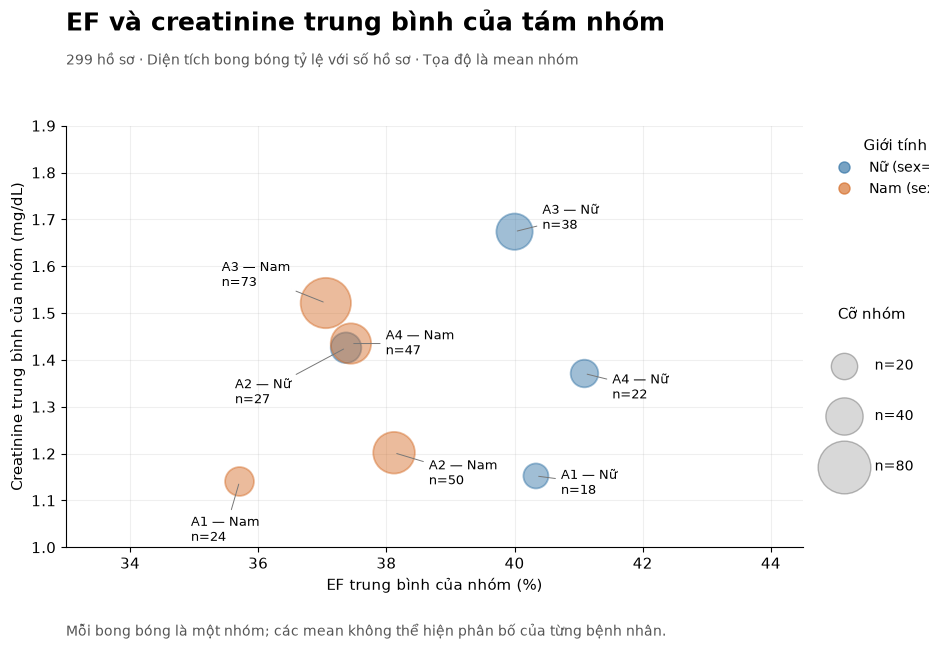

In [2]:
from matplotlib.lines import Line2D
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11})
fig, ax = plt.subplots(figsize=(11,6.8))
fig.subplots_adjust(top=0.80,bottom=0.18,left=0.10,right=0.77)
fig.text(0.10,0.94,"EF và creatinine trung bình của tám nhóm",fontsize=18,weight="bold")
fig.text(0.10,0.89,"299 hồ sơ · Diện tích bong bóng tỷ lệ với số hồ sơ · Tọa độ là mean nhóm",color="#555555",fontsize=10)
he_so_dien_tich = 18
for sex, mau, ten in [(0,"#2E70A3","Nữ (sex=0)"),(1,"#D46A24","Nam (sex=1)")]:
    nhom = bang_tong_hop.loc[bang_tong_hop["sex"].eq(sex)]
    diem = ax.scatter(nhom["EFMean"],nhom["CreatinineMean"],s=nhom["SoHoSo"]*he_so_dien_tich,
        color=mau,alpha=0.45,edgecolors=mau,linewidths=1.3,label=ten)
    assert np.allclose(diem.get_sizes(),nhom["SoHoSo"]*he_so_dien_tich)
assert sum(len(c.get_offsets()) for c in ax.collections)==8
do_lech = {(1,0):(18,-5),(1,1):(-35,-35),(2,0):(-80,-32),(2,1):(25,-15),
    (3,0):(20,10),(3,1):(-75,20),(4,0):(20,-10),(4,1):(25,0)}
for r in bang_tong_hop.to_dict("records"):
    ax.annotate(f'A{int(r["MaNhomTuoi"])} — {r["GioiTinh"]}\nn={r["SoHoSo"]}',
        xy=(r["EFMean"],r["CreatinineMean"]),xytext=do_lech[(int(r["MaNhomTuoi"]),int(r["sex"]))],
        textcoords="offset points",fontsize=9,ha="left",va="center",
        arrowprops={"arrowstyle":"-","color":"#777777","linewidth":0.7})
ax.set(xlabel="EF trung bình của nhóm (%)",ylabel="Creatinine trung bình của nhóm (mg/dL)",
    xlim=(33,44.5),ylim=(1.0,1.9))
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ky_hieu_gioi = [Line2D([],[],marker="o",linestyle="",markersize=8,color=m,alpha=0.65,label=t)
    for m,t in [("#2E70A3","Nữ (sex=0)"),("#D46A24","Nam (sex=1)")]]
lg = ax.legend(handles=ky_hieu_gioi,frameon=False,loc="upper left",bbox_to_anchor=(1.02,1),title="Giới tính",fontsize=10)
ax.add_artist(lg)
co_mau = [ax.scatter([],[],s=n*he_so_dien_tich,color="#aaaaaa",alpha=0.45,edgecolors="#666666",label=f"n={n}") for n in [20,40,80]]
lg_co = ax.legend(handles=co_mau,frameon=False,loc="upper left",bbox_to_anchor=(1.02,0.60),title="Cỡ nhóm",labelspacing=2.6,handletextpad=1.2,fontsize=10)
fig.text(0.10,0.05,"Mỗi bong bóng là một nhóm; các mean không thể hiện phân bố của từng bệnh nhân.",fontsize=10,color="#555555")
fig.savefig(thu_muc_kq / "14_bubble_nhom.png",dpi=300,bbox_inches="tight",bbox_extra_artists=(lg,lg_co,*fig.texts),facecolor="white")
bang_tong_hop.to_csv(thu_muc_kq / "tong_hop_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

Đọc đồng thời vị trí, màu và diện tích bong bóng. Nhóm nam A3 có cỡ mẫu lớn nhất (73), nữ A1 nhỏ nhất (18). Hai nhóm có tọa độ gần nhau có thể chồng lấn; nhãn và đường dẫn chỉ rõ nhóm, không dịch mean để tạo khoảng cách giả.

Không suy ra mọi bệnh nhân trong một nhóm đều có chỉ số bằng mean. Hình không có khoảng tin cậy và không dùng để kết luận khác biệt có ý nghĩa thống kê hoặc quan hệ nhân quả. Tuổi, sex, EF và creatinine có thể chứa giá trị đã điền trong tiền xử lý. Khi gộp mean dùng cỡ nhóm làm trọng số; tám nhóm đại diện đủ 299 hồ sơ. File after giữ nguyên.
